<a href="https://colab.research.google.com/github/evlannikovoleg-prog/ML-Prof/blob/main/hw10/hw10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Памперсы или пиво? Рекомендательная система на данных Amazon


**Датасет:** [Amazon Review Data (2018)](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/), раздел *Small subsets for experimentation*.

## План ноутбука

1. **Выбор и загрузка датасета** — берём одно из «маленьких» подмножеств Amazon, чтобы всё считалось быстро.
2. **EDA** — распределение рейтингов, активность пользователей и товаров, длинный хвост, динамика во времени, пары товаров.
3. **Предобработка и leave-one-out** — последнее взаимодействие каждого пользователя уходит в тест.
4. **Модели** — популярность, item-item kNN (TF-IDF), ALS (implicit matrix factorization).
5. **Оценка качества** — HR@10, MRR@10, NDCG@10, Coverage@10.
6. **Анализ ошибок и выводы**.

> Идея названия «Памперсы или пиво?» — про поиск неочевидных связей между товарами. В датасете Amazon нет корзинных данных, поэтому мы будем искать совместную встречаемость товаров у одних и тех же пользователей.


## 0. Окружение и импорты

Ноутбук рассчитан на Google Colab или локальный Jupyter. Нужны `numpy`, `pandas`, `scipy`, `matplotlib` и `implicit`.


In [ ]:
%pip install -q implicit


Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import gzip
import json
import random
import urllib.request
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
os.environ["TQDM_DISABLE"] = "1"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import csr_matrix

from implicit.als import AlternatingLeastSquares
from implicit.nearest_neighbours import TFIDFRecommender

%matplotlib inline

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

CATEGORY = "Digital_Music"
K = 10
MIN_USER_INTERACTIONS = 5
MIN_ITEM_INTERACTIONS = 5
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

print("Категория:", CATEGORY)
print("Топ-K:", K)


Категория: Digital_Music
Топ-K: 10


## 1. Датасет: выбор и загрузка

Датасет Amazon Review Data (2018) содержит отзывы, метаданные товаров и связи «also bought / also viewed». Для учебного проекта нас интересуют **k-core подмножества** из раздела *Small subsets*: в них у каждого пользователя и товара есть минимум 5 отзывов, и они быстро скачиваются.

| Категория | 5-core отзывов | Размер `*_5.json.gz` |
|---|---:|---:|
| Software | 12 805 | ~5 MB |
| Luxury Beauty | 34 278 | ~7 MB |
| **Digital Music** | **169 781** | **~20 MB** |
| Video Games | 497 577 | ~154 MB |

Выбираем **Digital Music**:

* ~170 тыс. отзывов — помещается в память и считается за десятки секунд;
* достаточно плотная матрица, чтобы сравнивать модели;
* 5-core уменьшает проблему холодного старта.

Категорию можно поменять в ячейке с конфигом (`CATEGORY = ...`): код сам скачает нужный файл.


In [ ]:
BASE_URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall"
REVIEWS_URL = f"{BASE_URL}/{CATEGORY}_5.json.gz"
REVIEWS_PATH = DATA_DIR / f"{CATEGORY}_5.json.gz"


def download_if_needed(url, path):
    path = Path(path)
    if path.exists() and path.stat().st_size > 0:
        print(f"Файл уже есть: {path} ({path.stat().st_size / 1e6:.1f} MB)")
        return path
    print(f"Скачиваем {url}")
    urllib.request.urlretrieve(url, path)
    print(f"Готово: {path} ({path.stat().st_size / 1e6:.1f} MB)")
    return path


_ = download_if_needed(REVIEWS_URL, REVIEWS_PATH)


Файл уже есть: data\Digital_Music_5.json.gz (19.5 MB)


In [ ]:
def read_amazon_reviews(path):
    rows = []
    with gzip.open(path, "rt", encoding="utf-8") as f:
        for line in f:
            obj = json.loads(line)
            rows.append({
                "user_id": obj["reviewerID"],
                "item_id": obj["asin"],
                "rating": float(obj["overall"]),
                "timestamp": int(obj.get("unixReviewTime", 0)),
            })
    frame = pd.DataFrame(rows)
    frame["review_date"] = pd.to_datetime(frame["timestamp"], unit="s")
    return frame


df = read_amazon_reviews(REVIEWS_PATH)
print(f"Строк (отзывов): {len(df):,}")
print(f"Пользователей: {df.user_id.nunique():,}")
print(f"Товаров: {df.item_id.nunique():,}")
print(f"Диапазон дат: {df.review_date.min().date()} — {df.review_date.max().date()}")
display(df.head(3))


Строк (отзывов): 169,781
Пользователей: 16,566
Товаров: 11,797
Диапазон дат: 1998-07-09 — 2018-09-26


,user_id,item_id,rating,timestamp,review_date
0,A2TYZ821XXK2YZ,3426958910,5.0,1370217600,2013-06-03
1,A3OFSREZADFUDY,3426958910,5.0,1412985600,2014-10-11
2,A2VAMODP8M77NG,3426958910,5.0,1392076800,2014-02-11


## 2. EDA

### 2.1. Базовая статистика

Смотрим размер данных, разреженность матрицы «пользователи × товары», дубликаты пар `user-item` и распределение рейтингов.


In [ ]:
n_rows = len(df)
n_users_raw = df.user_id.nunique()
n_items_raw = df.item_id.nunique()
raw_sparsity = 1 - n_rows / (n_users_raw * n_items_raw)
dup_pairs = df.duplicated(["user_id", "item_id"]).sum()

print(f"Наблюдений: {n_rows:,}")
print(f"Пользователей: {n_users_raw:,}")
print(f"Товаров: {n_items_raw:,}")
print(f"Разреженность матрицы: {raw_sparsity:.6f} ({raw_sparsity * 100:.4f}%)")
print(f"Дубликатов пар user-item: {dup_pairs:,} ({dup_pairs / n_rows:.2%})")
print(f"Средний рейтинг: {df.rating.mean():.3f}")
print(f"Доля отзывов с rating >= 4: {(df.rating >= 4).mean():.2%}")


Наблюдений: 169,781


Пользователей: 16,566
Товаров: 11,797
Разреженность матрицы: 0.999131 (99.9131%)
Дубликатов пар user-item: 24,489 (14.42%)
Средний рейтинг: 4.700
Доля отзывов с rating >= 4: 93.64%


### 2.2. Распределение рейтингов

В Amazon-отзывах ярко выражен перекос в сторону положительных оценок: пользователи чаще пишут отзыв, если товар понравился. Это важно помнить: рейтинг — *explicit* feedback, но его распределение сильно смещено.


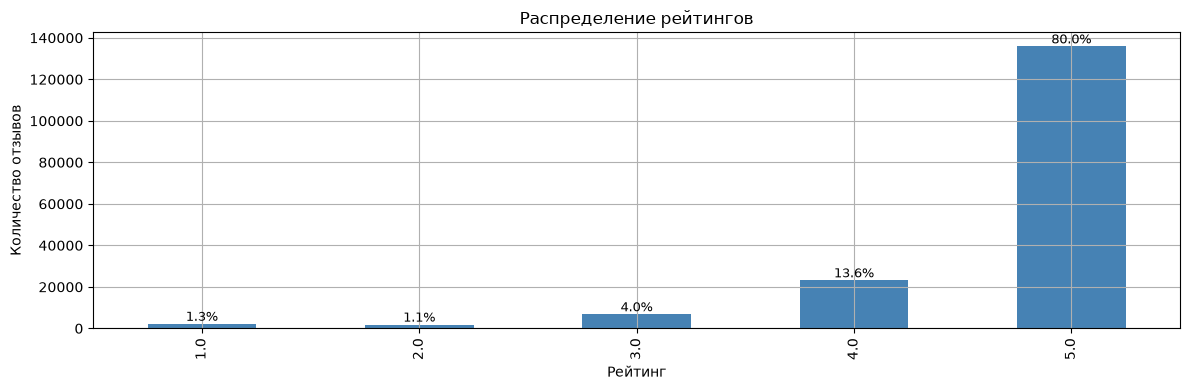

In [ ]:
rating_counts = df["rating"].value_counts().sort_index()
ax = rating_counts.plot(kind="bar", color="steelblue")
ax.set_title("Распределение рейтингов")
ax.set_xlabel("Рейтинг")
ax.set_ylabel("Количество отзывов")
for i, v in enumerate(rating_counts.values):
    ax.text(i, v, f"{v / n_rows:.1%}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()


### 2.3. Активность пользователей и товаров

Смотрим, сколько взаимодействий приходится на пользователя и на товар. Распределения имеют длинный хвост: большинство пользователей имеют единицы взаимодействий, а популярность товаров распределена неравномерно — топ-10% товаров собирают около 38% отзывов.


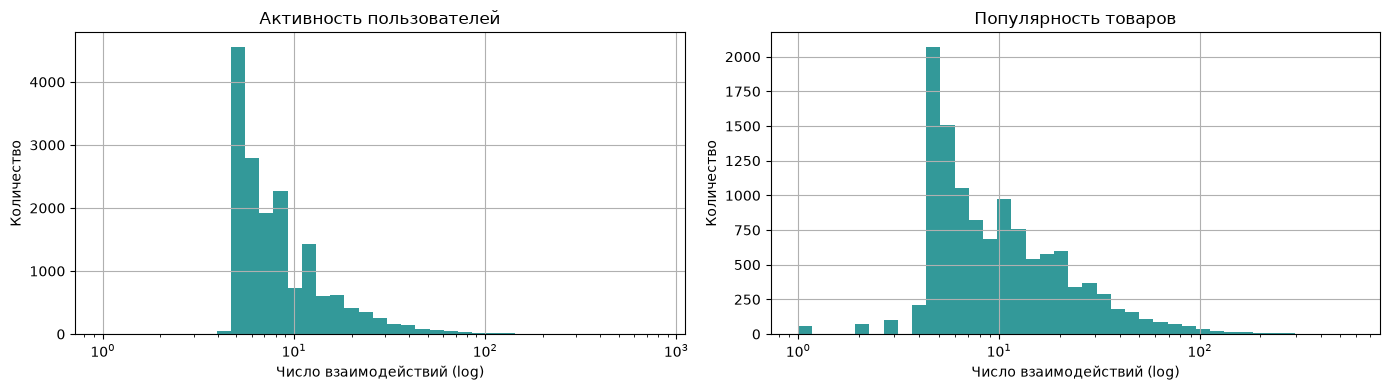

,пользователи,товары
q0,1.0,1.0
q25,5.0,6.0
q50,7.0,9.0
q75,11.0,15.0
q90,18.0,29.0
q99,54.0,91.0


In [ ]:
user_activity = df.groupby("user_id").size()
item_activity = df.groupby("item_id").size()


def log_hist_bins(series):
    if series.max() <= 1:
        return np.arange(0.5, series.max() + 1.5, 1)
    return np.logspace(0, np.log10(series.max()), 40)


fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, series, title in zip(
    axes,
    [user_activity, item_activity],
    ["Активность пользователей", "Популярность товаров"],
):
    ax.hist(series, bins=log_hist_bins(series), color="teal", alpha=0.8)
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel("Число взаимодействий (log)")
    ax.set_ylabel("Количество")
plt.tight_layout()
plt.show()

quantiles = [0, 0.25, 0.5, 0.75, 0.9, 0.99]
activity_summary = pd.DataFrame(
    {
        "пользователи": user_activity.quantile(quantiles).values,
        "товары": item_activity.quantile(quantiles).values,
    },
    index=[f"q{int(q * 100)}" for q in quantiles],
)
display(activity_summary)


### 2.4. Длинный хвост и топ популярных товаров

Проверим, какая доля взаимодействий сосредоточена в топ-1% и топ-10% товаров. Это объясняет, почему популярностная модель почти не даёт покрытия каталога: все пользователи получают примерно один и тот же короткий список.


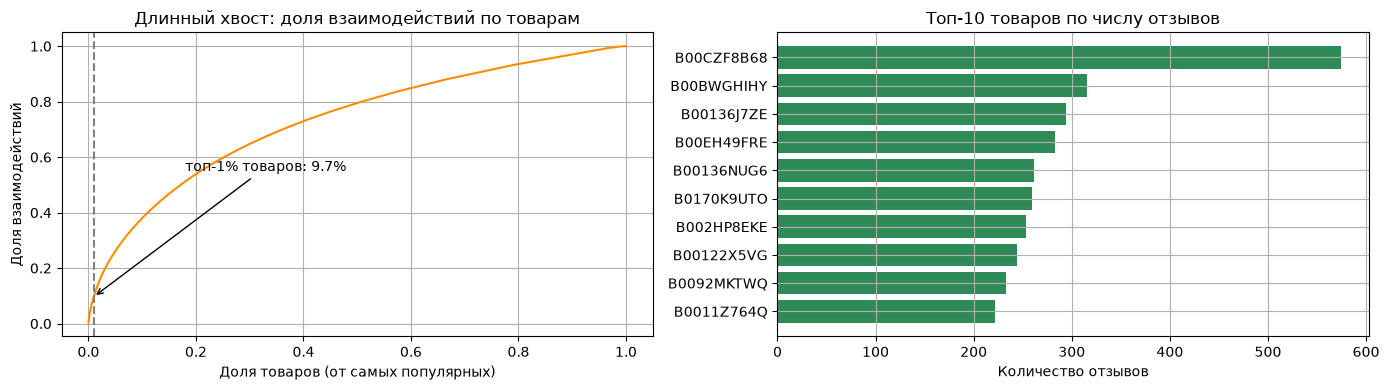

Топ-1% товаров дают 9.69% всех взаимодействий
Топ-10% товаров дают 38.01% всех взаимодействий


In [ ]:
item_activity_sorted = item_activity.sort_values(ascending=False)
cum_share = item_activity_sorted.cumsum() / item_activity_sorted.sum()
x_share = np.arange(1, len(item_activity_sorted) + 1) / len(item_activity_sorted)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(x_share, cum_share, color="darkorange")
axes[0].set_title("Длинный хвост: доля взаимодействий по товарам")
axes[0].set_xlabel("Доля товаров (от самых популярных)")
axes[0].set_ylabel("Доля взаимодействий")

top1_cut = cum_share.iloc[max(0, int(0.01 * len(cum_share)) - 1)]
axes[0].axvline(0.01, color="gray", linestyle="--")
axes[0].annotate(
    f"топ-1% товаров: {top1_cut:.1%}",
    xy=(0.01, top1_cut),
    xytext=(0.18, 0.55),
    arrowprops=dict(arrowstyle="->"),
)

top10_items = item_activity_sorted.head(10)[::-1]
axes[1].barh(top10_items.index.astype(str), top10_items.values, color="seagreen")
axes[1].set_title("Топ-10 товаров по числу отзывов")
axes[1].set_xlabel("Количество отзывов")
plt.tight_layout()
plt.show()

print(f"Топ-1% товаров дают {top1_cut:.2%} всех взаимодействий")
print(f"Топ-10% товаров дают {cum_share.iloc[int(0.1 * len(cum_share)) - 1]:.2%} всех взаимодействий")


### 2.5. Динамика во времени

Смотрим, как менялось количество отзывов и средний рейтинг по месяцам. Это помогает понять, есть ли выраженный дрейф предпочтений и насколько корректен временной порядок при leave-one-out.


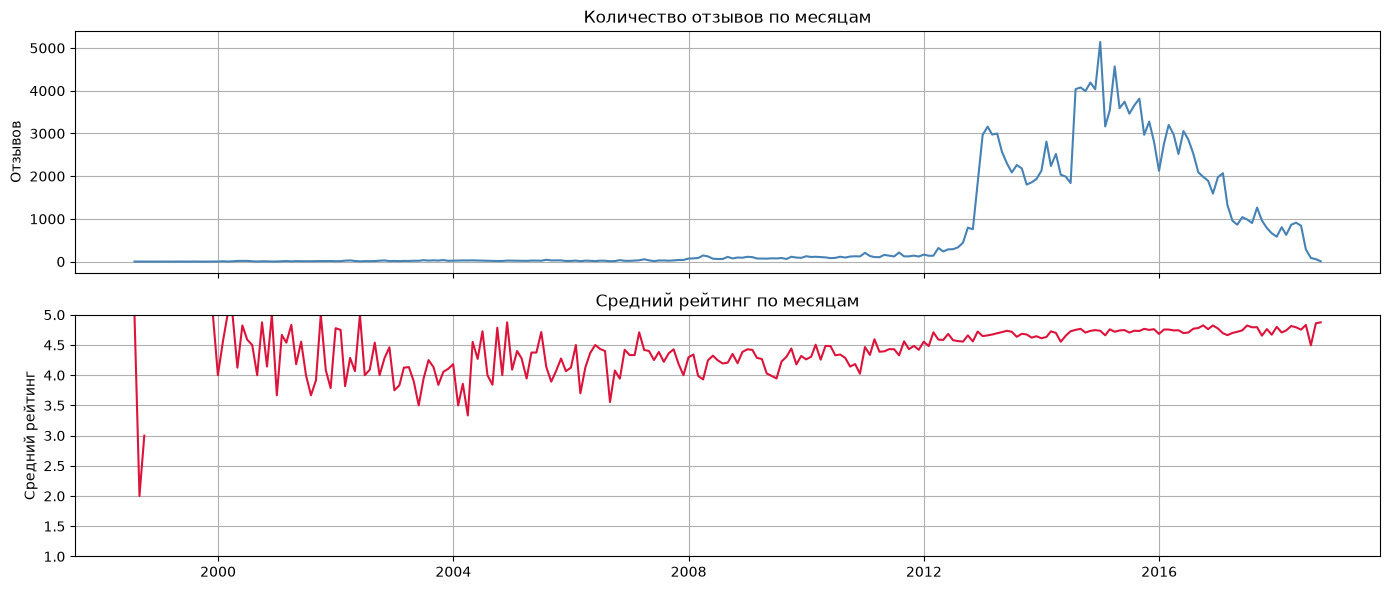

In [ ]:
monthly_count = df.set_index("review_date").resample("ME").size()
monthly_rating = df.set_index("review_date").resample("ME")["rating"].mean()

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(monthly_count.index, monthly_count.values, color="steelblue")
axes[0].set_title("Количество отзывов по месяцам")
axes[0].set_ylabel("Отзывов")
axes[1].plot(monthly_rating.index, monthly_rating.values, color="crimson")
axes[1].set_title("Средний рейтинг по месяцам")
axes[1].set_ylabel("Средний рейтинг")
axes[1].set_ylim(1, 5)
plt.tight_layout()
plt.show()


### 2.6. «Памперсы или пиво»: какие товары встречаются вместе

Корзинных данных в датасете нет, но можно построить матрицу совместной встречаемости: два товара «встречаются», если их оценил один и тот же пользователь. Чтобы популярные товары не доминировали, нормируем на косинус и сортируем пары по числу общих пользователей (поддержке).

Косинус 1.0 означает, что товары оценили практически одни и те же пользователи — например, переиздания или варианты одного альбома. Это **описательный** анализ: он показывает, что в данных действительно есть устойчивые пары товаров. Модель item-item kNN ниже использует ровно эту идею, но считает похожесть только по train.


In [ ]:
pairs = df.drop_duplicates(["user_id", "item_id"])
user_codes_eda = pd.Categorical(pairs["user_id"]).codes
item_index_eda = pd.Categorical(pairs["item_id"]).categories
item_codes_eda = pd.Categorical(pairs["item_id"]).codes

R_eda = csr_matrix(
    (np.ones(len(pairs), dtype=np.float32), (user_codes_eda, item_codes_eda)),
    shape=(pairs.user_id.nunique(), len(item_index_eda)),
)
co = (R_eda.T @ R_eda).tocoo()
norms = np.sqrt(np.asarray(R_eda.sum(axis=0)).ravel())

row, col, data = co.row, co.col, co.data
upper = row < col
row, col, data = row[upper], col[upper], data[upper]
cosine = data / (norms[row] * norms[col] + 1e-12)

co_df = pd.DataFrame({
    "item_a": item_index_eda.take(row),
    "item_b": item_index_eda.take(col),
    "common_users": data,
    "cosine": cosine,
})
co_df = (
    co_df[co_df.common_users >= 20]
    .sort_values(["common_users", "cosine"], ascending=False)
    .head(10)
)
print("Товары, которые пользователи чаще всего оценивают вместе:")
display(co_df.reset_index(drop=True))


Товары, которые пользователи чаще всего оценивают вместе:


,item_a,item_b,common_users,cosine
0,B00330WKMA,B00GDL60JU,143.0,0.944764
1,B00137KRYS,B00EE0O6HU,95.0,0.960037
2,B000S51XMQ,B006H1ME5A,85.0,1.000000
3,B004DH2F8Q,B00PN14AKC,68.0,0.992727
4,B000VZJS20,B00150S5HY,52.0,1.000000
5,B00BWGHIHY,B00CZF8B68,49.0,0.116176
6,B00137QMFG,B00137SPH4,46.0,1.000000
7,B00CZF8B68,B00EH49FRE,42.0,0.105514
8,B00123FMKM,B0012FDNHY,41.0,1.000000
9,B002IEW504,B002NQTG5Y,41.0,0.281529


### 2.7. Выводы по EDA

* Рейтинги смещены в сторону 4–5 звёзд, поэтому разумно рассматривать взаимодействие как положительный сигнал (implicit feedback).
* Матрица очень разреженная: подавляющее большинство пар пользователь × товар не наблюдаются.
* Есть длинный хвост: топ-10% товаров дают около 38% взаимодействий, а медианный пользователь имеет 7 отзывов.
* В данных есть повторные отзывы на одну и ту же пару `user-item` — перед моделированием их нужно схлопнуть.
* Совместная встречаемость товаров существует, значит neighbourhood-модели (item-item kNN) должны работать.


## 3. Предобработка и leave-one-out

### 3.1. Дедупликация и k-core

1. Оставляем последний по времени отзыв для каждой пары `user-item`.
2. Дополнительно фильтруем k-core: у каждого пользователя и каждого товара должно остаться минимум 5 взаимодействий. Это уменьшает шум и холодный старт.


In [ ]:
def filter_k_core(frame, min_user=MIN_USER_INTERACTIONS, min_item=MIN_ITEM_INTERACTIONS):
    frame = frame.copy()
    while True:
        n_before = len(frame)
        item_counts = frame.groupby("item_id").size()
        frame = frame[frame["item_id"].isin(item_counts[item_counts >= min_item].index)]
        user_counts = frame.groupby("user_id").size()
        frame = frame[frame["user_id"].isin(user_counts[user_counts >= min_user].index)]
        if len(frame) == n_before:
            return frame.reset_index(drop=True)


print(f"До дедупликации: {len(df):,} строк")
df = (
    df.sort_values(["user_id", "timestamp"], kind="mergesort")
      .drop_duplicates(["user_id", "item_id"], keep="last")
      .reset_index(drop=True)
)
print(
    f"После дедупликации: {len(df):,} строк, "
    f"{df.user_id.nunique():,} пользователей, {df.item_id.nunique():,} товаров"
)

df = filter_k_core(df)
print(
    f"После {MIN_USER_INTERACTIONS}-core фильтрации: {len(df):,} строк, "
    f"{df.user_id.nunique():,} пользователей, {df.item_id.nunique():,} товаров"
)


До дедупликации: 169,781 строк


После дедупликации: 145,292 строк, 16,566 пользователей, 11,797 товаров


После 5-core фильтрации: 123,518 строк, 12,381 пользователей, 9,906 товаров


### 3.2. Leave-one-out

Сортируем взаимодействия по пользователю и времени, последнее взаимодействие каждого пользователя уходит в тест, остальное — в train. Так получается ровно один целевой товар на пользователя.


In [ ]:
df = df.sort_values(["user_id", "timestamp"], kind="mergesort").reset_index(drop=True)

test = df.groupby("user_id", sort=False).tail(1).copy()
train = df.drop(test.index).copy().reset_index(drop=True)
test_target = (
    test[["user_id", "item_id"]]
    .rename(columns={"item_id": "target_item_id"})
    .reset_index(drop=True)
)

print(
    f"Train: {len(train):,} взаимодействий, "
    f"{train.user_id.nunique():,} пользователей, {train.item_id.nunique():,} товаров"
)
print(f"Test: {len(test_target):,} пользователей (по одному целевому товару)")
print(f"Минимум взаимодействий в train у пользователя: {train.groupby('user_id').size().min()}")

assert test_target["user_id"].is_unique, "В тесте должен быть ровно один объект на пользователя"


Train: 111,137 взаимодействий, 12,381 пользователей, 9,905 товаров
Test: 12,381 пользователей (по одному целевому товару)
Минимум взаимодействий в train у пользователя: 4


In [ ]:
train_items = set(train["item_id"])
cold_mask = ~test_target["target_item_id"].isin(train_items)
print(
    f"Целевых товаров, которых нет в train-каталоге: {cold_mask.sum():,} "
    f"({cold_mask.mean():.2%})"
)
test_target = test_target[~cold_mask].reset_index(drop=True)

history_len = train.groupby("user_id").size().rename("history_len")
test_target = test_target.merge(history_len, left_on="user_id", right_index=True, how="left")

print(f"Итоговый test: {len(test_target):,} пользователей")
display(test_target["history_len"].describe().to_frame().T)


Целевых товаров, которых нет в train-каталоге: 6 (0.05%)
Итоговый test: 12,375 пользователей


,count,mean,std,min,25%,50%,75%,max
history_len,12375.0,8.974626,10.834563,4.0,4.0,6.0,9.0,528.0


## 4. Модели

### 4.1. Общая постановка

* **Implicit feedback:** факт взаимодействия считаем положительным сигналом. Для item-item kNN и популярностной модели используем бинарную матрицу.
* **Explicit feedback:** рейтинг используем как вес уверенности для ALS (чем выше оценка, тем сильнее сигнал).
* **Уже просмотренные товары** исключаем из рекомендаций (`filter_already_liked_items=True`).
* Качество измеряем на последнем (leave-one-out) товаре пользователя.

Строим внутренние индексы и разреженные матрицы взаимодействий.


In [ ]:
user_cat = pd.Index(train["user_id"].unique())
item_cat = pd.Index(train["item_id"].unique())
user2id = {user: i for i, user in enumerate(user_cat)}
item2id = {item: i for i, item in enumerate(item_cat)}
uid2user = {i: user for user, i in user2id.items()}
iid2item = {i: item for item, i in item2id.items()}

n_users, n_items = len(user_cat), len(item_cat)
rows = train["user_id"].map(user2id).to_numpy()
cols = train["item_id"].map(item2id).to_numpy()

train_matrix = csr_matrix(
    (np.ones(len(train), dtype=np.float32), (rows, cols)),
    shape=(n_users, n_items),
)

als_values = train["rating"].astype(np.float32).to_numpy()
als_matrix = csr_matrix((als_values, (rows, cols)), shape=(n_users, n_items))

test_users = test_target["user_id"].to_numpy()
test_uid = np.array([user2id[user] for user in test_users])

print(f"Матрица взаимодействий: {train_matrix.shape}")
print(f"Непустых элементов: {train_matrix.nnz:,}")
print(f"Разреженность: {1 - train_matrix.nnz / (n_users * n_items):.6f}")


Матрица взаимодействий: (12381, 9905)
Непустых элементов: 111,137
Разреженность: 0.999094


In [ ]:
def recs_from_implicit(model, userids, user_items, id2item, uid2user, k=10):
    item_ids, scores = model.recommend(
        userids, user_items, N=k, filter_already_liked_items=True
    )
    frames = []
    for uid, ids, sc in zip(userids, item_ids, scores):
        valid = ids >= 0
        ids, sc = ids[valid], sc[valid]
        frames.append(
            pd.DataFrame({
                "uid": uid,
                "item_id": [id2item[int(i)] for i in ids],
                "score": sc,
                "rank": np.arange(1, len(ids) + 1),
            })
        )
    recs = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    if not recs.empty:
        recs["user_id"] = recs["uid"].map(uid2user)
    return recs[["user_id", "item_id", "score", "rank"]]


def evaluate_recommender(recs, targets, n_catalog_items, k=10):
    targets = targets[["user_id", "target_item_id"]].drop_duplicates()
    recs_k = recs[recs["rank"] <= k]
    merged = recs_k.merge(
        targets,
        left_on=["user_id", "item_id"],
        right_on=["user_id", "target_item_id"],
        how="inner",
    )
    hit_rank = merged.groupby("user_id")["rank"].min()
    all_users = targets["user_id"].unique()

    hr = hit_rank.reindex(all_users).notna().mean()
    mrr = (1.0 / hit_rank).reindex(all_users, fill_value=0).mean()
    ndcg = (1.0 / np.log2(hit_rank + 1)).reindex(all_users, fill_value=0).mean()
    coverage = recs_k["item_id"].nunique() / n_catalog_items

    return {
        f"HR@{k}": hr,
        f"MRR@{k}": mrr,
        f"NDCG@{k}": ndcg,
        f"Coverage@{k}": coverage,
        "n_users": len(all_users),
    }


### 4.2. Модель 1: популярность (baseline)

Самый простой бейзлайн: рекомендуем топ-K самых популярных товаров train, исключая уже просмотренные. Он не персонализирован, но задаёт нижнюю границу качества.


In [ ]:
def popularity_recommendations(train, test_users, k=10, candidate_pool=2000):
    item_counts = train.groupby("item_id").size().sort_values(ascending=False)
    catalog = item_counts.index.tolist()
    candidates = catalog[: max(candidate_pool, k)]
    seen = train.groupby("user_id")["item_id"].apply(set)

    frames = []
    for user in test_users:
        user_seen = seen.get(user, set())
        picked = [item for item in candidates if item not in user_seen][:k]
        if len(picked) < k:
            picked += [
                item for item in catalog
                if item not in user_seen and item not in picked
            ][: k - len(picked)]
        frames.append(
            pd.DataFrame({
                "user_id": user,
                "item_id": picked,
                "score": item_counts.reindex(picked).to_numpy(),
                "rank": np.arange(1, len(picked) + 1),
            })
        )
    return pd.concat(frames, ignore_index=True)


pop_recs = popularity_recommendations(train, test_users, K)
print(
    f"Популярностная модель: {len(pop_recs):,} рекомендаций "
    f"для {pop_recs.user_id.nunique():,} пользователей"
)
display(pop_recs.head())


Популярностная модель: 123,750 рекомендаций для 12,375 пользователей


,user_id,item_id,score,rank
0,A0072041HVZ3465DXUOR,B00BWGHIHY,261,1
1,A0072041HVZ3465DXUOR,B00EH49FRE,242,2
2,A0072041HVZ3465DXUOR,B0092MKTWQ,206,3
3,A0072041HVZ3465DXUOR,B002HP8EKE,203,4
4,A0072041HVZ3465DXUOR,B0170K9UTO,198,5


### 4.3. Модель 2: item-item kNN с TF-IDF

Идея: если пользователю понравился товар A, рекомендуем товары, которые часто встречаются вместе с A у других пользователей.

* Считаем косинусную похожесть между товарами.
* Взвешивание **TF-IDF** снижает вклад сверхпопулярных товаров и помогает покрытию каталога.
* Берём K=50 соседей и исключаем уже виденные товары.


In [ ]:
item_knn = TFIDFRecommender(K=50)
item_knn.fit(train_matrix, show_progress=False)
knn_recs = recs_from_implicit(item_knn, test_uid, train_matrix[test_uid], iid2item, uid2user, K)
print(
    f"ItemKNN (TF-IDF): {len(knn_recs):,} рекомендаций "
    f"для {knn_recs.user_id.nunique():,} пользователей"
)
display(knn_recs.head())


ItemKNN (TF-IDF): 123,746 рекомендаций для 12,375 пользователей


,user_id,item_id,score,rank
0,A0072041HVZ3465DXUOR,B004Y154KC,0.818142,1
1,A0072041HVZ3465DXUOR,B0092MKTWQ,0.712279,2
2,A0072041HVZ3465DXUOR,B00DHAKLNG,0.622777,3
3,A0072041HVZ3465DXUOR,B00AZH2I9E,0.617990,4
4,A0072041HVZ3465DXUOR,B00F0AIE4E,0.607865,5


### 4.4. Модель 3: ALS (implicit matrix factorization)

ALS раскладывает матрицу взаимодействий на латентные факторы пользователей и товаров. В implicit-версии рейтинг можно использовать как вес уверенности: чем выше оценка, тем сильнее модель стремится сохранить эту связь.

Параметры: `factors=192`, `regularization=0.01`, `alpha=40`, `iterations=30`. Это компромисс между качеством и временем обучения на CPU.


In [ ]:
als = AlternatingLeastSquares(
    factors=192,
    regularization=0.01,
    alpha=40,
    iterations=30,
    random_state=RANDOM_STATE,
    use_gpu=False,
)
als.fit(als_matrix, show_progress=False)
als_recs = recs_from_implicit(als, test_uid, als_matrix[test_uid], iid2item, uid2user, K)
print(
    f"ALS: {len(als_recs):,} рекомендаций "
    f"для {als_recs.user_id.nunique():,} пользователей"
)
display(als_recs.head())


ALS: 123,750 рекомендаций для 12,375 пользователей


,user_id,item_id,score,rank
0,A0072041HVZ3465DXUOR,B006OITIWS,0.826355,1
1,A0072041HVZ3465DXUOR,B00DDFC0D4,0.760168,2
2,A0072041HVZ3465DXUOR,B005T18DOK,0.698720,3
3,A0072041HVZ3465DXUOR,B009G78GRW,0.680686,4
4,A0072041HVZ3465DXUOR,B00EH49FRE,0.677399,5


## 5. Оценка качества рекомендаций

Считаем стандартные метрики ранжирования на leave-one-out:

* **HR@10** — доля пользователей, у которых целевой товар попал в топ-10.
* **MRR@10** — среднее обратное ранга первого попадания (0, если попадания нет).
* **NDCG@10** — качество ранжирования с логарифмическим дисконтированием (для одного релевантного товара).
* **Coverage@10** — доля каталога train, которая встретилась хотя бы в одном топ-10.


In [ ]:
results = {
    "Popularity": evaluate_recommender(pop_recs, test_target, n_items, K),
    "ItemKNN (TF-IDF)": evaluate_recommender(knn_recs, test_target, n_items, K),
    "ALS (implicit MF)": evaluate_recommender(als_recs, test_target, n_items, K),
}
results_df = pd.DataFrame(results).T

metric_cols = [f"HR@{K}", f"MRR@{K}", f"NDCG@{K}", f"Coverage@{K}"]
results_percent = (results_df[metric_cols] * 100).round(2)
results_percent["n_users"] = results_df["n_users"].astype(int)

print(f"Метрики в процентах (K = {K})")
display(results_percent)
results_percent.to_csv("recsys_results.csv")


Метрики в процентах (K = 10)


,HR@10,MRR@10,NDCG@10,Coverage@10,n_users
Popularity,1.66,0.67,0.90,0.19,12375
ItemKNN (TF-IDF),11.61,6.61,7.78,95.85,12375
ALS (implicit MF),10.91,5.39,6.68,88.74,12375


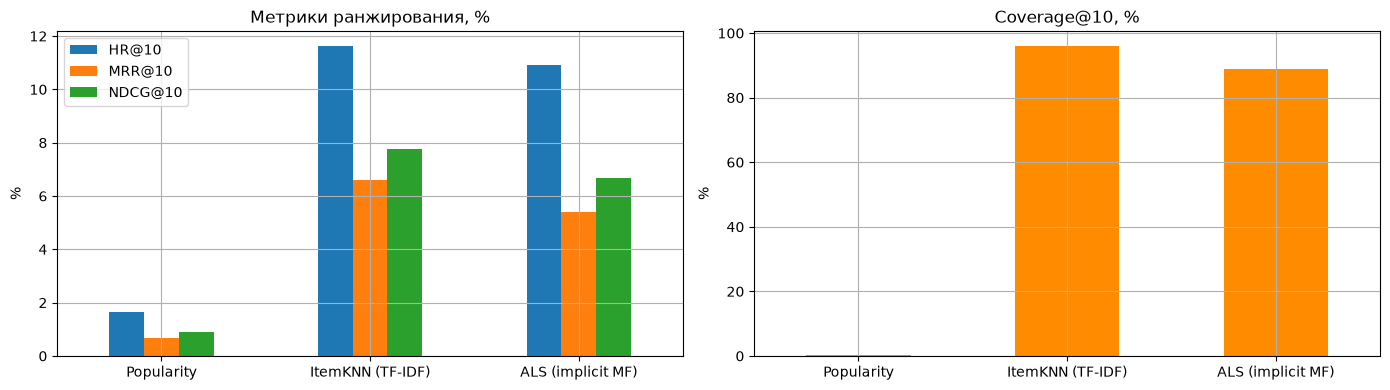

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

results_percent[[f"HR@{K}", f"MRR@{K}", f"NDCG@{K}"]].plot(
    kind="bar", ax=axes[0], rot=0
)
axes[0].set_title("Метрики ранжирования, %")
axes[0].set_ylabel("%")

results_percent[[f"Coverage@{K}"]].plot(
    kind="bar", ax=axes[1], rot=0, color="darkorange", legend=False
)
axes[1].set_title(f"Coverage@{K}, %")
axes[1].set_ylabel("%")

plt.tight_layout()
plt.show()


## 6. Анализ ошибок

### 6.1. Зависимость от длины истории пользователя

Ожидаемо, что чем больше у пользователя истории, тем проще персонализировать рекомендации. Проверим это по всем трём моделям.


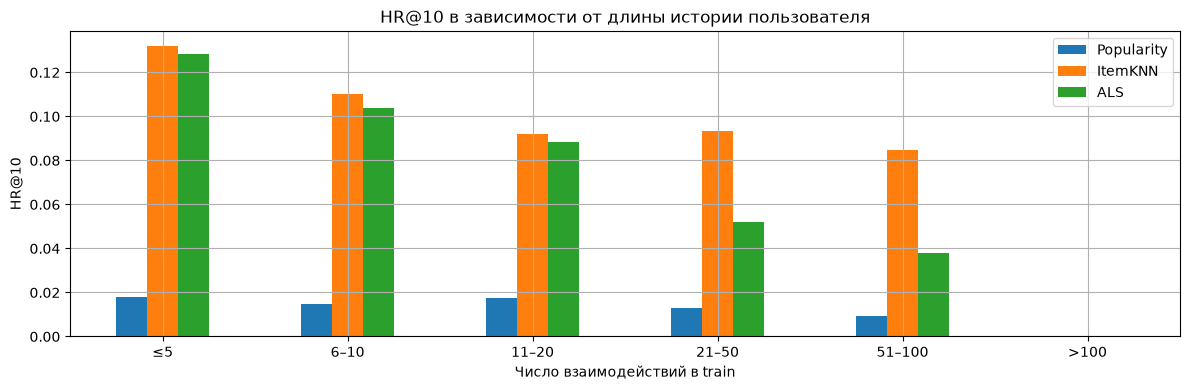

In [ ]:
def with_hits(recs, targets, k=10):
    recs_k = recs[recs["rank"] <= k]
    merged = recs_k.merge(
        targets[["user_id", "target_item_id"]],
        left_on=["user_id", "item_id"],
        right_on=["user_id", "target_item_id"],
        how="inner",
    )
    frame = targets.copy()
    frame["hit"] = frame["user_id"].isin(merged["user_id"])
    return frame


bins = [0, 5, 10, 20, 50, 100, 10_000]
labels = ["≤5", "6–10", "11–20", "21–50", "51–100", ">100"]

hit_by_history = {}
for name, recs in [("Popularity", pop_recs), ("ItemKNN", knn_recs), ("ALS", als_recs)]:
    frame = with_hits(recs, test_target, K)
    frame["bucket"] = pd.cut(frame["history_len"], bins=bins, labels=labels, right=True)
    hit_by_history[name] = frame.groupby("bucket", observed=True)["hit"].mean()

pd.DataFrame(hit_by_history).plot(kind="bar", figsize=(12, 4), rot=0)
plt.title(f"HR@{K} в зависимости от длины истории пользователя")
plt.ylabel(f"HR@{K}")
plt.xlabel("Число взаимодействий в train")
plt.tight_layout()
plt.show()


### 6.2. Зависимость от популярности целевого товара

Проверим, насколько модели справляются с длинным хвостом: разбиваем целевые товары на квинтили по популярности в train и смотрим HR@10.


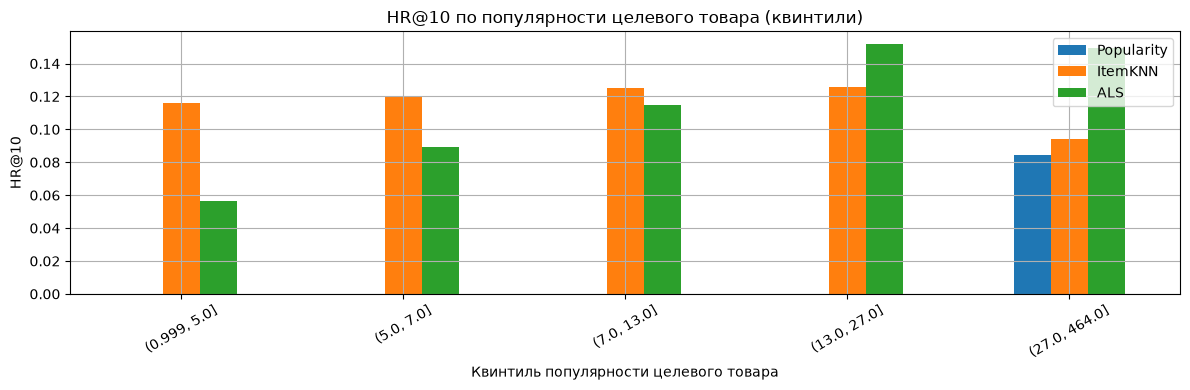

In [ ]:
item_popularity = train.groupby("item_id").size().rename("item_popularity")
targets_pop = test_target.merge(
    item_popularity, left_on="target_item_id", right_index=True, how="left"
)
targets_pop["target_pop_bucket"] = pd.qcut(
    targets_pop["item_popularity"], 5, duplicates="drop"
)

hit_by_pop = {}
for name, recs in [("Popularity", pop_recs), ("ItemKNN", knn_recs), ("ALS", als_recs)]:
    frame = with_hits(recs, targets_pop, K)
    hit_by_pop[name] = frame.groupby("target_pop_bucket", observed=True)["hit"].mean()

pd.DataFrame(hit_by_pop).plot(kind="bar", figsize=(12, 4), rot=30)
plt.title(f"HR@{K} по популярности целевого товара (квинтили)")
plt.ylabel(f"HR@{K}")
plt.xlabel("Квинтиль популярности целевого товара")
plt.tight_layout()
plt.show()


### 6.3. Пример рекомендаций для одного пользователя

Возьмём пользователя с длинной историей, для которого ItemKNN попал в целевой товар, и посмотрим, какие товары рекомендуют модели.


In [ ]:
knn_hits = knn_recs[knn_recs["rank"] <= K].merge(
    test_target[["user_id", "target_item_id"]],
    left_on=["user_id", "item_id"],
    right_on=["user_id", "target_item_id"],
    how="inner",
)
example_user = (
    test_target[test_target.user_id.isin(knn_hits.user_id)]
    .sort_values("history_len", ascending=False)
    .iloc[0]["user_id"]
)
target_item = test_target.loc[test_target.user_id == example_user, "target_item_id"].iloc[0]
history_items = train.loc[train.user_id == example_user, "item_id"].tolist()

print(f"Пользователь: {example_user}")
print(f"Длина истории: {len(history_items)}")
print(f"Целевой товар (leave-one-out): {target_item}")
print("История (первые 15 товаров):", history_items[:15])

for name, recs in [("Popularity", pop_recs), ("ItemKNN", knn_recs), ("ALS", als_recs)]:
    top = (
        recs[(recs.user_id == example_user) & (recs["rank"] <= K)]
        [["rank", "item_id", "score"]]
        .reset_index(drop=True)
    )
    hit = target_item in set(top["item_id"])
    print(f"\n{name}: целевой товар в топ-{K}? {hit}")
    display(top)


Пользователь: A2RNYF2PTOB82J
Длина истории: 83
Целевой товар (leave-one-out): B00JNOL4VI
История (первые 15 товаров): ['B002C6CIWI', 'B000QP4IBG', 'B000T1EJ0W', 'B000V64UXQ', 'B000VRQQRS', 'B000VZYFOQ', 'B000W00IGY', 'B000W18M3Y', 'B0011Z0ZU8', 'B001229HBS', 'B0012EJGRG', 'B00136JD9Y', 'B00136JCGS', 'B00136LDKQ', 'B00136LQUI']

Popularity: целевой товар в топ-10? False


,rank,item_id,score
0,1,B00CZF8B68,464
1,2,B00BWGHIHY,261
2,3,B00EH49FRE,242
3,4,B0092MKTWQ,206
4,5,B002HP8EKE,203
5,6,B0170K9UTO,198
6,7,B00JLJ185C,185
7,8,B004NYNGTQ,172
8,9,B006Z1XZFK,158
9,10,B002IEW504,157



ItemKNN: целевой товар в топ-10? True


,rank,item_id,score
0,1,B00JNOL4VI,1.332060
1,2,B000TRVI5U,0.977303
2,3,B00137Z1VM,0.903763
3,4,B001GD3MOG,0.862834
4,5,B000TRZ1VM,0.859159
5,6,B003W2A96I,0.814895
6,7,B006GN7G2A,0.805348
7,8,B00163NVM4,0.802389
8,9,B001A7FFIY,0.750953
9,10,B00137Z1W6,0.745611



ALS: целевой товар в топ-10? False


,rank,item_id,score
0,1,B0011Z94L4,1.055161
1,2,B0015FW76O,1.023842
2,3,B001BKAEJA,0.926281
3,4,B00163NVM4,0.870322
4,5,B00137Z22A,0.856297
5,6,B001A7HBZO,0.849226
6,7,B001O4UCO0,0.828050
7,8,B00136RLAM,0.823291
8,9,B002WQ0TN8,0.804900
9,10,B001KSDIKK,0.782674


## 7. Выводы

### Что получилось

| Модель | HR@10 | MRR@10 | NDCG@10 | Coverage@10 |
|---|---:|---:|---:|---:|
| Popularity | 1.66% | 0.67% | 0.90% | 0.19% |
| **ItemKNN (TF-IDF)** | **11.61%** | **6.61%** | **7.78%** | **95.85%** |
| ALS (implicit MF) | 10.91% | 5.39% | 6.68% | 88.74% |

* **Популярность** — самый слабый вариант по HR/MRR/NDCG. Это ожидаемо: модель не персонализирована. Зато она тривиально интерпретируется и служит нижней границей.
* **ItemKNN (TF-IDF)** — лучшая модель по HR@10 и NDCG@10, а также лидер по покрытию каталога. Идея «товары, которые встречаются вместе» хорошо работает на Amazon-данных.
* **ALS (implicit MF)** — совсем немного уступает ItemKNN: латентные факторы дают персонализацию и хорошее покрытие, но на разреженных данных и коротких историях neighbourhood-подход оказывается чуть точнее.

### Почему метрики невысокие в абсолюте

* Один целевой товар на пользователя — очень строгая постановка.
* Истории короткие (медиана ~6 взаимодействий в train).
* Матрица крайне разреженная (>99.9%).
* Мы игнорируем негативный фидбек: даже 1–2 звезды считаются взаимодействием.

### Что можно улучшить

1. **Валидация и подбор гиперпараметров**: отделить validation из train и настраивать `K`, `factors`, `alpha`, `regularization` без утечки теста.
2. **Контентные признаки**: LightFM с жанрами/брендом/категориями товаров (подход из `recsys_lightfm`).
3. **Нейросетевые модели**: BPR, NeuMF, SASRec.
4. **Работа с негативным фидбеком**: обучать только на `rating >= 4` или отдельно моделировать низкие оценки.
5. **Метрики**: добавить `replay-rec` (HitRate, NDCG, Coverage) и diversity/novelty.
6. **Холодный старт**: fallback на популярность для новых пользователей.
